# Longitudinal infant gut microbiome: alpha and beta diversity trajectories

**Goal:** This notebook looks at changes in infant gut microbiome diversity across age and differences between infants using precalculated QIIME 2 Shannon diversity values and a Bracken taxonomic abundance table.

1. Load the Shannon diversity values, sample metadata and Bracken abundance table.

2. Alpha diversity: Shannon diversity by age group (violin plot), a mixed-effects model with infant as random effect, and individual infant trajectories.

3. Beta diversity: Bray–Curtis dissimilarity between samples from the same infant vs. different infants, compared overall, by age gap and by exact age pair.

4. Variance partitioning (age vs. infant identity) and the pre-computed QIIME 2 PERMANOVA/PERMDISP results for age.



**Inputs** (in `micro_odyssey_data/`): 
`shannon_vector.qza`, `metadata_numage.tsv`, `bracken-table.qza`, and the QIIME 2 PERMANOVA/PERMDISP `.qzv` files.

**Outputs:** figures are written to `figures/`.

## 0. Setup

In [27]:
Path.cwd()

PosixPath('/home/jovyan')

In [28]:
from pathlib import Path
import numpy as np
import pandas as pd
import biom
import qiime2 as q2
import matplotlib.pyplot as plt
import seaborn as sns
from skbio import DistanceMatrix

%matplotlib inline

# paths
data_dir = Path("micro_odyssey_data")
fig_dir = Path("MicroOdyssey/scripts/04_longitudinal analysis/figures")
fig_dir.mkdir(exist_ok=True)

# Plot settings
sns.set_theme(style="whitegrid", context="talk")

AGES = [0, 2, 6, 12, 24]
AGE_LABELS = ["Birth", "2 months", "6 months", "12 months", "24 months"]
AGE_PALETTE = sns.color_palette("mako", len(AGES))
COMP_COLORS = {"Same infant": "#4A9D9D", "Different infants": "#53649A"}
DARK = "#17253A"

# save figures
def save_fig(name):
    plt.savefig(fig_dir / name, dpi=300, bbox_inches="tight")

## 1. Load data

In [29]:
# Alpha diversity (Shannon) per sample
shannon = q2.Artifact.load(data_dir / "shannon_vector.qza").view(pd.Series).rename("Shannon")
# -> gives the pandas Series the label "Shannon"

# Sample metadata
meta = pd.read_csv(data_dir / "metadata_numage.tsv", sep="\t", index_col=0)

# Taxonomic abundance table (Bracken): samples x taxa
biom_table = q2.Artifact.load(data_dir / "bracken-table.qza").view(biom.Table)
abundance = biom_table.to_dataframe(dense=True).T

print("Abundance table (samples x taxa):", abundance.shape)
print("Samples with metadata:", abundance.index.isin(meta.index).sum(), "/", len(abundance))

Abundance table (samples x taxa): (234, 15034)
Samples with metadata: 234 / 234


## 2. Alpha diversity across infant development

### 2.1 Cross-sectional view: Shannon diversity by age group
The violin plot groups samples by age but does not show which samples belong to the same infant,
so it cannot say whether individual infants follow different trajectories (see 2.3).

In [30]:
# one table used for all alpha-diversity analyses: Shannon + age + infant ID

alpha = shannon.to_frame().join(meta[["age_months", "host_id"]]).dropna()
alpha["Age"] = pd.Categorical(
    alpha["age_months"].astype(int).map(dict(zip(AGES, AGE_LABELS))),
    categories=AGE_LABELS, ordered=True,
)
print(f"{len(alpha)} samples from {alpha['host_id'].nunique()} infants")
display(alpha.head())

228 samples from 55 infants


,Shannon,age_months,host_id,Age
SRR25052449,4.898670,24.0,246,24 months
SRR25052450,3.891334,12.0,246,12 months
SRR25052451,2.724143,6.0,246,6 months
SRR25052452,3.223777,2.0,246,2 months
SRR25052453,0.742019,0.0,246,Birth


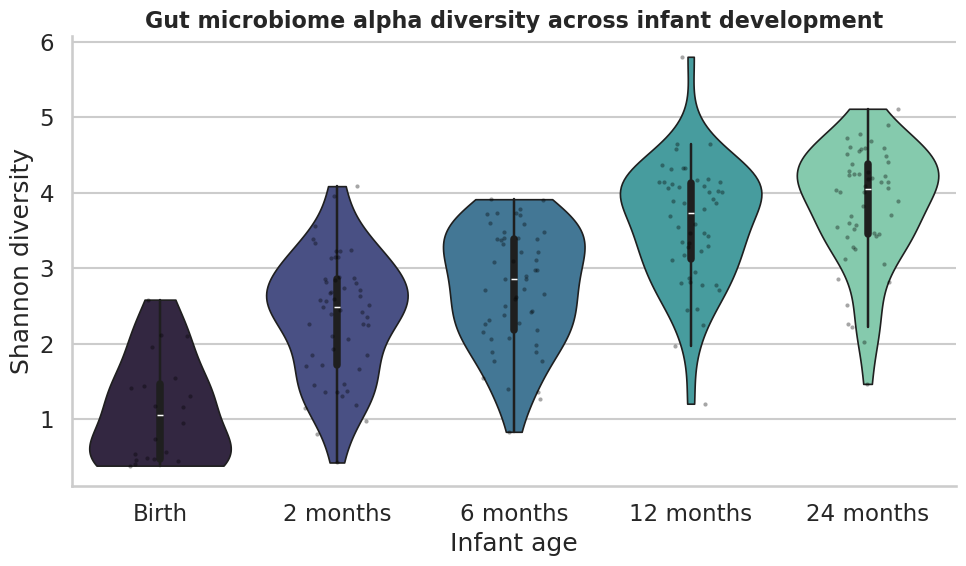

In [31]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.violinplot(
    data=alpha, x="Age", y="Shannon", order=AGE_LABELS,
    hue="Age", palette=AGE_PALETTE, legend=False,
    inner="box", cut=0, linewidth=1.2, ax=ax,
)
sns.stripplot(
    data=alpha, x="Age", y="Shannon", order=AGE_LABELS,
    color="black", size=3, alpha=0.35, jitter=0.18, ax=ax,
)

ax.set_xlabel("Infant age")
ax.set_ylabel("Shannon diversity")
ax.set_title("Gut microbiome alpha diversity across infant development", fontsize=16, weight="bold")
sns.despine()
plt.tight_layout()
save_fig("shannon_violin.png")
plt.show()

### 2.2 Mixed-effects model: Shannon ~ age, random intercept per infant

Since we have multiple samples from the same infant, we use a random intercept to account for this. The model assumes that diversity changes linearly with age, but since samples were collected at different intervals (0, 2, 6, 12 and 24 months), we should check whether this is reasonabe. (We could also try a log-transformed age or allow the effect of age to vary between infants.)

In [32]:
!qiime longitudinal linear-mixed-effects \
    --m-metadata-file $data_dir/metadata_numage.tsv \
    --m-metadata-file $data_dir/shannon_vector.qza \
    --p-metric shannon_entropy \
    --p-state-column age_months \
    --p-individual-id-column host_id \
    --o-visualization $data_dir/shannon_LME.qzv

Saved Visualization to: micro_odyssey_data/shannon_LME.qzv


In [13]:
q2.Visualization.load(data_dir / "shannon_LME.qzv")

<visualization: Visualization uuid: d1fa3bee-cedc-42d5-a8f8-352ebab3d4ae>

### 2.3 Individual infant trajectories
Thin lines connect samples from the same infant; the dark line is the mean per age.

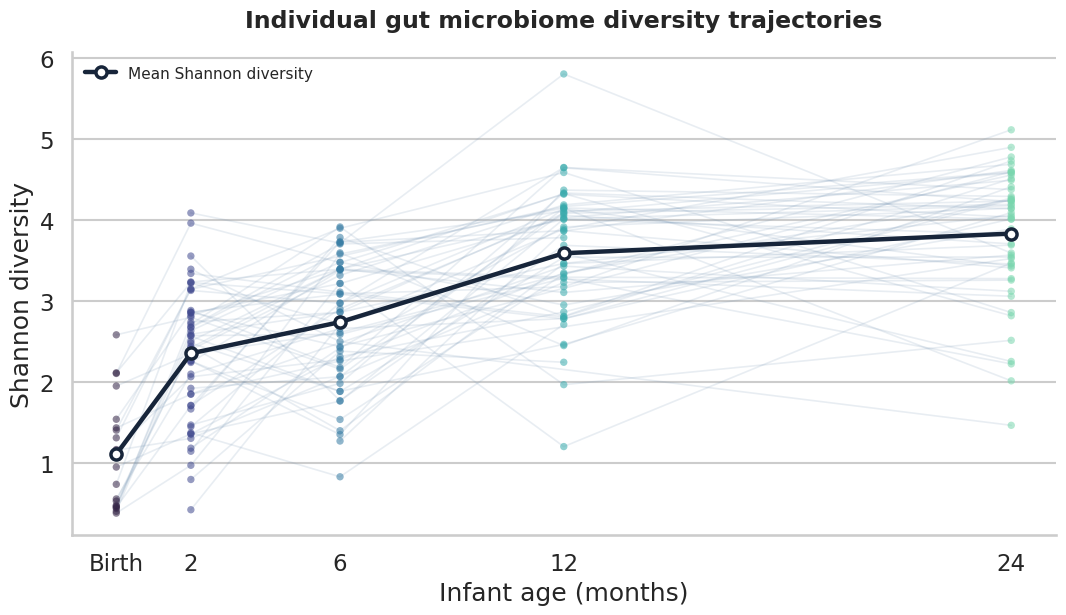

In [33]:
fig, ax = plt.subplots(figsize=(11, 6.5))

# 1. Individual infant trajectories (light)
for _, grp in alpha.groupby("host_id"):
    grp = grp.sort_values("age_months")
    ax.plot(grp["age_months"], grp["Shannon"], color="#7393B3", alpha=0.16, linewidth=1.2, zorder=1)

# 2. Individual samples, coloured by age
for age, colour in zip(AGES, AGE_PALETTE):
    sub = alpha[alpha["age_months"] == age]
    ax.scatter(sub["age_months"], sub["Shannon"], color=colour, alpha=0.55, s=28, edgecolors="none", zorder=2)

# 3. Mean per age
mean_shannon = alpha.groupby("age_months")["Shannon"].mean().reindex(AGES)
ax.plot(AGES, mean_shannon, color=DARK, linewidth=3.2, marker="o", markersize=8,
        markerfacecolor="white", markeredgewidth=2.5, label="Mean Shannon diversity", zorder=5)

ax.set_xticks(AGES)
ax.set_xticklabels(["Birth", "2", "6", "12", "24"])
ax.set_xlabel("Infant age (months)")
ax.set_ylabel("Shannon diversity")
ax.set_title("Individual gut microbiome diversity trajectories", fontsize=17, fontweight="bold", pad=18)
ax.legend(frameon=False, loc="upper left", fontsize=11)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
save_fig("shannon_trajectories.png")
plt.show()

## 3. Beta diversity: same infant vs. different infants

### 3.1 Import QIIME 2 Bray–Curtis distance matrix

The precomputed Bray–Curtis distance matrix is imported
from QIIME 2 and converted into a pandas DataFrame
for downstream pairwise comparisons.

In [34]:
bray = q2.Artifact.load(data_dir / "bray_curtis_distance_matrix.qza").view(DistanceMatrix).to_data_frame()

print("Bray-Curtis distance matrix:", bray.shape)
display(bray.head())

Bray-Curtis distance matrix: (228, 228)


,SRR25052449,SRR25052450,SRR25052451,SRR25052452,SRR25052453,SRR25052454,SRR25052455,SRR25052456,SRR25052458,SRR25052459,...,SRR25052710,SRR25052711,SRR25052712,SRR25052713,SRR25052714,SRR25052715,SRR25052716,SRR25052717,SRR25052719,SRR25052720
SRR25052449,0.000000,0.707403,0.635504,0.785782,0.937052,0.562182,0.743200,0.709203,0.532390,0.563163,...,0.587893,0.473976,0.552326,0.756616,0.833831,0.930126,0.428856,0.663085,0.835791,0.938208
SRR25052450,0.707403,0.000000,0.832530,0.716321,0.509861,0.789014,0.618821,0.591794,0.758461,0.746863,...,0.744852,0.791381,0.796567,0.800167,0.871947,0.508620,0.676182,0.825107,0.477747,0.517320
SRR25052451,0.635504,0.832530,0.000000,0.462225,0.950567,0.793327,0.839865,0.848283,0.801683,0.821659,...,0.824868,0.692314,0.597103,0.773637,0.731198,0.943094,0.666649,0.799469,0.873553,0.950030
SRR25052452,0.785782,0.716321,0.462225,0.000000,0.827718,0.844537,0.748838,0.757831,0.855255,0.877615,...,0.853209,0.794228,0.742648,0.707162,0.870438,0.825225,0.702732,0.853557,0.752691,0.828572
SRR25052453,0.937052,0.509861,0.950567,0.827718,0.000000,0.957139,0.718949,0.686245,0.961395,0.960336,...,0.961318,0.961272,0.943607,0.865279,0.954011,0.044537,0.872910,0.953524,0.546752,0.051080


### 3.2 Build one table of all sample pairs
Every pairwise comparison is computed **once** here and reused by all plots below. 

Columns:
infant and age of each sample, whether the pair is from the same infant, the age gap, and the distance.


Note that pairs are *not independent* (each sample appears in many pairs), so boxplots are descriptive;
formal tests should use permutation/mixed-model approaches (Section 5).

In [35]:
# keep samples that are in the distance matrix and have complete metadata
info = meta.loc[bray.index.intersection(meta.index), ["host_id", "age_months"]].dropna()
D = bray.loc[info.index, info.index].to_numpy()

# all unique sample pairs (upper triangle)
i, j = np.triu_indices(len(info), k=1)
host = info["host_id"].to_numpy()
age = info["age_months"].to_numpy().astype(int)

pairs_all = pd.DataFrame({
    "Sample1": info.index[i], "Sample2": info.index[j],
    "Same_infant": host[i] == host[j],
    "Age1": np.minimum(age[i], age[j]),     # younger sample of the pair
    "Age2": np.maximum(age[i], age[j]),     # older sample of the pair
    "Bray_Curtis": D[i, j],
})
pairs_all["Age_gap"] = pairs_all["Age2"] - pairs_all["Age1"]
pairs_all["Age_pair"] = pairs_all["Age1"].astype(str) + "–" + pairs_all["Age2"].astype(str)
pairs_all["Comparison"] = np.where(pairs_all["Same_infant"], "Same infant", "Different infants")

# pairs at different ages: the fair like-for-like comparison of same vs different infants
# we remove pairs with the same age-
pairs = pairs_all[pairs_all["Age_gap"] > 0].copy()

# compare Bray–Curtis distances
print(f"{len(pairs_all):,} pairs in total; {len(pairs):,} at different ages")
display(pairs.groupby("Comparison")["Bray_Curtis"].describe().round(3))

25,878 pairs in total; 20,381 at different ages


,count,mean,std,min,25%,50%,75%,max
Comparison,,,,,,,,
Different infants,20010.0,0.785,0.154,0.062,0.715,0.831,0.898,0.968
Same infant,371.0,0.740,0.181,0.110,0.636,0.783,0.880,0.965


### (3.3 Overall: same infant vs. different infants (different ages only))
Descriptive overview. Because the mix of age gaps differs between the two groups, the age-matched
comparison in 3.4 is the more reliable one.

In [ ]:
order = ["Same infant", "Different infants"]

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(
    data=pairs, x="Comparison", y="Bray_Curtis", order=order,
    hue="Comparison", palette=COMP_COLORS, legend=False,
    width=0.48, linewidth=1.5, showfliers=False,
    medianprops={"color": DARK, "linewidth": 2.5}, ax=ax,
)

medians = pairs.groupby("Comparison")["Bray_Curtis"].median()
for k, grp in enumerate(order):
    ax.text(k, medians[grp] + 0.045, f"Median: {medians[grp]:.2f}",
            ha="center", fontsize=12, fontweight="bold", color=DARK)

ax.set_title("Microbial community dissimilarity within vs. between infants", fontsize=16, fontweight="bold", pad=20)
ax.set_xlabel("")
ax.set_ylabel("Bray–Curtis dissimilarity")
ax.set_ylim(0, 1.05)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
save_fig("bray_curtis_same_vs_different_infant.png")
plt.show()

### (3.4 Age-matched comparison by age gap)
Only age gaps observed in *both* groups are kept, so same-infant and different-infant pairs are compared at equal time separation.

In [ ]:
gap_counts = pd.crosstab(pairs["Age_gap"], pairs["Comparison"])
valid_gaps = gap_counts.index[(gap_counts["Same infant"] > 0) & (gap_counts["Different infants"] > 0)]
pairs_matched = pairs[pairs["Age_gap"].isin(valid_gaps)].copy()

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=pairs_matched, x="Age_gap", y="Bray_Curtis",
    hue="Comparison", hue_order=order, palette=COMP_COLORS,
    showfliers=False, width=0.7, ax=ax,
)
ax.set_title("Microbial dissimilarity by infant identity and age gap", fontsize=16, fontweight="bold")
ax.set_xlabel("Age difference between samples (months)")
ax.set_ylabel("Bray–Curtis dissimilarity")
ax.legend(title="", frameon=False, fontsize=11)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
save_fig("bray_curtis_age_matched.png")
plt.show()

### 3.5 Exact age pairs: median dissimilarity, same vs. different infants
(e.g., 2→6 months) 

Δ = different-infant median − same-infant median;
- a positive Δ means samples from the same infant are more similar. The sample counts (`n_*`) show how much each estimate rests on.

In [36]:
def age_pair_key(label):
    a, b = label.split("–")
    return (int(a), int(b))

summary = pairs.groupby(["Age_pair", "Comparison"])["Bray_Curtis"].agg(["median", "size"]).unstack()
summary.columns = [f"{'n' if stat == 'size' else 'median'}_{grp}" for stat, grp in summary.columns]
summary = summary.loc[sorted(summary.index, key=age_pair_key)]
summary["Difference"] = summary["median_Different infants"] - summary["median_Same infant"]
display(summary.round(3))

,median_Different infants,median_Same infant,n_Different infants,n_Same infant,Difference
Age_pair,,,,,
0–2,0.934,0.910,1040,20,0.024
0–6,0.926,0.931,1041,19,-0.006
0–12,0.925,0.907,982,18,0.018
0–24,0.926,0.910,1020,20,0.016
2–6,0.793,0.636,2758,51,0.158
2–12,0.843,0.805,2602,48,0.038
2–24,0.861,0.850,2706,50,0.011
6–12,0.769,0.707,2602,48,0.061
6–24,0.809,0.785,2706,50,0.024


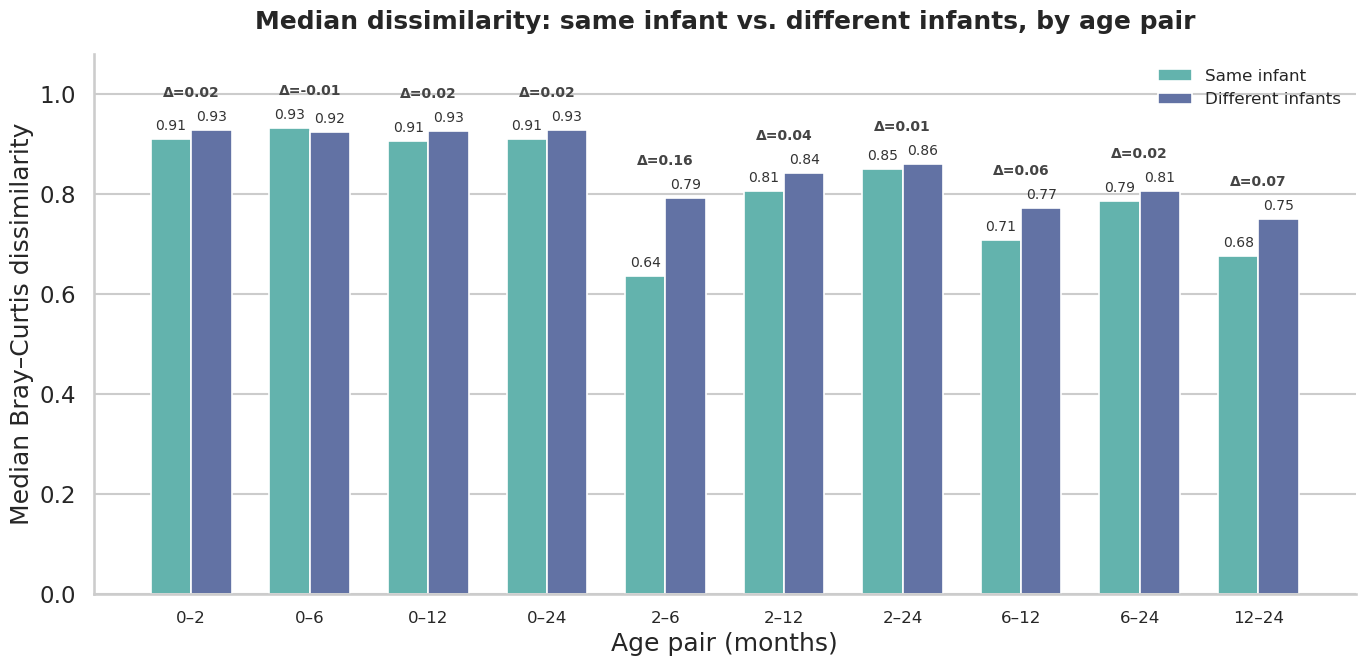

In [42]:
age_labels = perm_results["Age pair"].tolist()
same_vals = perm_results["Within median"].to_numpy()
diff_vals = perm_results["Between median"].to_numpy()
delta = diff_vals - same_vals

x = np.arange(len(age_labels))
width = 0.34

fig, ax = plt.subplots(figsize=(14, 7))
bars1 = ax.bar(x - width/2, same_vals, width, label="Same infant", color="#63B3AD", edgecolor="white", linewidth=1.2)
bars2 = ax.bar(x + width/2, diff_vals, width, label="Different infants", color="#6272A4", edgecolor="white", linewidth=1.2)

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.012, f"{h:.2f}",
            ha="center", va="bottom", fontsize=10, color="#333333")

for k, d in enumerate(delta):
    ax.text(x[k], max(same_vals[k], diff_vals[k]) + 0.06, f"Δ={d:.2f}",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="#444444")

ax.set_xticks(x)
ax.set_xticklabels(age_labels, fontsize=12)
ax.set_xlabel("Age pair (months)")
ax.set_ylabel("Median Bray–Curtis dissimilarity")
ax.set_title("Median dissimilarity: same infant vs. different infants, by age pair", fontsize=18, fontweight="bold", pad=18)
ax.set_ylim(0, 1.08)
ax.legend(frameon=False, fontsize=12, loc="upper right")
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
save_fig("bray_curtis_exact_age_pairs.png")
plt.show()

### 3.6 Permutation test for infant-specific similarity

In [40]:
from itertools import combinations
from statsmodels.stats.multitest import multipletests

rng = np.random.default_rng(42)
n_perm = 9999 # repeat 9999 times
results = []

for a, b in combinations(AGES, 2):
    m1 = info[info["age_months"] == a].sort_values("host_id")
    m2 = info[info["age_months"] == b].sort_values("host_id")

    # select infants sampled at both ages
    common = set(m1["host_id"]) & set(m2["host_id"])
    m1 = m1[m1["host_id"].isin(common)]
    m2 = m2[m2["host_id"].isin(common)]

    D = bray.loc[m1.index, m2.index].to_numpy()
    n = len(common)
    same = np.eye(n, dtype=bool)

    # calculate observed median difference
    within = np.median(D[same])
    between = np.median(D[~same])
    observed = between - within

    # random infant matching
    null = np.empty(n_perm)
    for i in range(n_perm):
        mask = same[:, rng.permutation(n)]
        null[i] = np.median(D[~mask]) - np.median(D[mask])

    p = (1 + np.sum(null >= observed)) / (n_perm + 1)
    results.append([f"{a}–{b}", n, within, between, observed, p])

perm_results = pd.DataFrame(results, columns=[
    "Age pair", "Infants", "Within median",
    "Between median", "Difference", "p-value"
])
# holm correction
perm_results["Adjusted p-value"] = multipletests(
    perm_results["p-value"], method="holm"
)[1]

display(perm_results.round(4))

,Age pair,Infants,Within median,Between median,Difference,p-value,Adjusted p-value
0,0–2,20,0.9099,0.9281,0.0182,0.0689,0.3342
1,0–6,19,0.9315,0.9236,-0.0078,0.5900,0.5900
2,0–12,18,0.9066,0.9256,0.0190,0.0557,0.3342
3,0–24,20,0.9098,0.9287,0.0188,0.0602,0.3342
4,2–6,51,0.6358,0.7926,0.1569,0.0003,0.0030
5,2–12,48,0.8051,0.8419,0.0369,0.0150,0.1050
6,2–24,50,0.8499,0.8600,0.0101,0.1144,0.3342
7,6–12,48,0.7074,0.7721,0.0646,0.0013,0.0117
8,6–24,50,0.7854,0.8061,0.0207,0.0678,0.3342
9,12–24,47,0.6755,0.7495,0.0740,0.0028,0.0224


In [41]:
display(perm_results[[
    "Age pair", "Within median", "Between median"
]].round(3))

,Age pair,Within median,Between median
0,0–2,0.910,0.928
1,0–6,0.931,0.924
2,0–12,0.907,0.926
3,0–24,0.910,0.929
4,2–6,0.636,0.793
5,2–12,0.805,0.842
6,2–24,0.850,0.860
7,6–12,0.707,0.772
8,6–24,0.785,0.806
9,12–24,0.675,0.749


### (3.6 Separating the two sources of variation)
Two complementary views: how different are infants *from each other at the same age*, and how much does a *single infant* change across each age interval.

In [ ]:
between = pairs_all[(~pairs_all["Same_infant"]) & (pairs_all["Age_gap"] == 0)].copy()   # different infants, same age
within = pairs_all[pairs_all["Same_infant"] & (pairs_all["Age_gap"] > 0)].copy()        # same infant, different ages
within["Interval"] = within["Age_pair"]
interval_order = sorted(within["Interval"].unique(), key=age_pair_key)

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=between, x="Age1", y="Bray_Curtis", color=COMP_COLORS["Different infants"], showfliers=False, ax=ax)
ax.set_title("Between-infant microbial differences by age")
ax.set_xlabel("Infant age (months)")
ax.set_ylabel("Bray–Curtis dissimilarity")
sns.despine(); plt.tight_layout()
save_fig("between_infants_by_age.png")
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=within, x="Interval", y="Bray_Curtis", order=interval_order,
            color=COMP_COLORS["Same infant"], showfliers=False, ax=ax)
ax.set_title("Within-infant microbial changes across age intervals")
ax.set_xlabel("Age interval (months)")
ax.set_ylabel("Bray–Curtis dissimilarity")
ax.tick_params(axis="x", rotation=45)
sns.despine(); plt.tight_layout()
save_fig("within_infant_by_interval.png")
plt.show()

## (4. Variance partitioning: age vs. infant identity)
PERMANOVA-style R² for one factor at a time: R² = 1 − SS_within / SS_total, computed directly from the distance matrix.

**Caution.** Raw R² grows with the number of groups. Infant ID has ~55 groups of ~4 samples each, whereas age has 5 groups,
so the raw R² for infant identity is inflated. The adjusted R² corrects for this and is the fair comparison.

In [14]:
def variance_explained(D, groups):
    """R² = 1 - SS_within / SS_total for a distance matrix D and a grouping vector."""
    groups = np.asarray(groups)
    n = len(groups)
    ss_total = (D ** 2).sum() / (2 * n)
    ss_within = 0.0
    for g in np.unique(groups):
        idx = np.where(groups == g)[0]
        ss_within += (D[np.ix_(idx, idx)] ** 2).sum() / (2 * len(idx))
    return 1 - ss_within / ss_total

def adjusted_r2(r2, n, g):
    return 1 - (1 - r2) * (n - 1) / (n - g)

n = len(info)
rows = []
for label, col in [("Age", "age_months"), ("Infant (host_id)", "host_id")]:
    r2 = variance_explained(D, info[col])
    g = info[col].nunique()
    rows.append({"Factor": label, "Groups": g, "R²": r2, "Adjusted R²": adjusted_r2(r2, n, g)})

variance_table = pd.DataFrame(rows).set_index("Factor")
display(variance_table.round(3))

,Groups,R²,Adjusted R²
Factor,,,
Age,5,0.151,0.136
Infant (host_id),55,0.283,0.066


## 5. QIIME 2 PERMANOVA / PERMDISP (age)
Pre-computed with QIIME 2 (`beta-group-significance`). PERMANOVA tests whether group centroids differ;
PERMDISP tests whether group dispersions differ. A significant PERMANOVA is only cleanly interpretable as a
location effect if PERMDISP is not also significant.

In [10]:
q2.Visualization.load(data_dir / "braycurtis_permanova_host_age.qzv")

<visualization: Visualization uuid: fa4210e7-c2f9-4939-bb16-1f724da520a4>

In [11]:
q2.Visualization.load(data_dir / "braycurtis_permdisp_host_age.qzv")

<visualization: Visualization uuid: 5e39a850-e7d0-4fd9-bdf8-c6e06253fc09>